이 노트북은 <[케라스 창시자에게 배우는 딥러닝 (개정 3판)](https://tensorflow.blog/kerasdl3/)>(길벗, 2026)의 예제 코드를 담고 있습니다.

## 텐서플로, 파이토치, JAX 그리고 케라스에 대한 소개

### 딥러닝 프레임워크의 간략한 역사

### 프레임워크 사이의 관계

### 텐서플로 소개

#### 텐서플로 첫걸음

##### 텐서플로의 텐서와 변수

###### 상수 텐서

In [4]:
import tensorflow as tf
tf.ones(shape=(2, 1))

<tf.Tensor: shape=(2, 1), dtype=float32, numpy=
array([[1.],
       [1.]], dtype=float32)>

In [5]:
tf.zeros(shape=(2, 1))

<tf.Tensor: shape=(2, 1), dtype=float32, numpy=
array([[0.],
       [0.]], dtype=float32)>

In [6]:
tf.constant([1, 2, 3], dtype="float32")

<tf.Tensor: shape=(3,), dtype=float32, numpy=array([1., 2., 3.], dtype=float32)>

###### 랜덤 텐서

In [7]:
x = tf.random.normal(shape=(3, 1), mean=0., stddev=1.)
print(x)

tf.Tensor(
[[ 1.1401967 ]
 [-0.17731655]
 [ 0.08205773]], shape=(3, 1), dtype=float32)


In [8]:
x = tf.random.uniform(shape=(3, 1), minval=0., maxval=1.)
print(x)

tf.Tensor(
[[0.88373697]
 [0.66843534]
 [0.00447369]], shape=(3, 1), dtype=float32)


###### 텐서 할당과 Variable 클래스

In [ ]:
import numpy as np

x = np.ones(shape=(2, 2))
x[0, 0] = 0.0

In [10]:
v = tf.Variable(initial_value=tf.random.normal(shape=(3, 1)))
print(v)

<tf.Variable 'Variable:0' shape=(3, 1) dtype=float32, numpy=
array([[-0.23014332],
       [ 1.8705312 ],
       [ 0.7865193 ]], dtype=float32)>


In [11]:
v.assign(tf.ones((3, 1)))

<tf.Variable 'UnreadVariable' shape=(3, 1) dtype=float32, numpy=
array([[1.],
       [1.],
       [1.]], dtype=float32)>

In [12]:
v[0, 0].assign(3.)

<tf.Variable 'UnreadVariable' shape=(3, 1) dtype=float32, numpy=
array([[3.],
       [1.],
       [1.]], dtype=float32)>

In [13]:
v.assign_add(tf.ones((3, 1)))

<tf.Variable 'UnreadVariable' shape=(3, 1) dtype=float32, numpy=
array([[4.],
       [2.],
       [2.]], dtype=float32)>

##### 텐서 연산: 텐서플로로 수학 계산하기

In [ ]:
a = tf.ones((2, 2))
b = tf.square(a)
c = tf.sqrt(a)
d = b + c
e = tf.matmul(a, b)
f = tf.concat((a, b), axis=0)

In [ ]:
def dense(inputs, W, b):
    return tf.nn.relu(tf.matmul(inputs, W) + b)

##### 텐서플로의 그레이디언트: GradientTape API 다시 살펴 보기

In [ ]:
input_var = tf.Variable(initial_value=3.0)
with tf.GradientTape() as tape:
    result = tf.square(input_var)
gradient = tape.gradient(result, input_var)

In [ ]:
input_const = tf.constant(3.0)
with tf.GradientTape() as tape:
    tape.watch(input_const)
    result = tf.square(input_const)
gradient = tape.gradient(result, input_const)

In [ ]:
time = tf.Variable(0.0)
with tf.GradientTape() as outer_tape:
    with tf.GradientTape() as inner_tape:
        position = 4.9 * time**2
    speed = inner_tape.gradient(position, time)
acceleration = outer_tape.gradient(speed, time)

##### 컴파일을 사용해 텐서플로 함수 속도 높이기

In [ ]:
@tf.function
def dense(inputs, W, b):
    return tf.nn.relu(tf.matmul(inputs, W) + b)

In [ ]:
@tf.function(jit_compile=True)
def dense(inputs, W, b):
    return tf.nn.relu(tf.matmul(inputs, W) + b)

#### 엔드-투-엔드 예제: 순수 텐서플로로 구현하는 선형 분류기

In [ ]:
import numpy as np

num_samples_per_class = 1000
negative_samples = np.random.multivariate_normal(
    mean=[0, 3], cov=[[1, 0.5], [0.5, 1]], size=num_samples_per_class
)
positive_samples = np.random.multivariate_normal(
    mean=[3, 0], cov=[[1, 0.5], [0.5, 1]], size=num_samples_per_class
)

In [ ]:
inputs = np.vstack((negative_samples, positive_samples)).astype(np.float32)

In [ ]:
targets = np.vstack(
    (
        np.zeros((num_samples_per_class, 1), dtype="float32"),
        np.ones((num_samples_per_class, 1), dtype="float32"),
    )
)

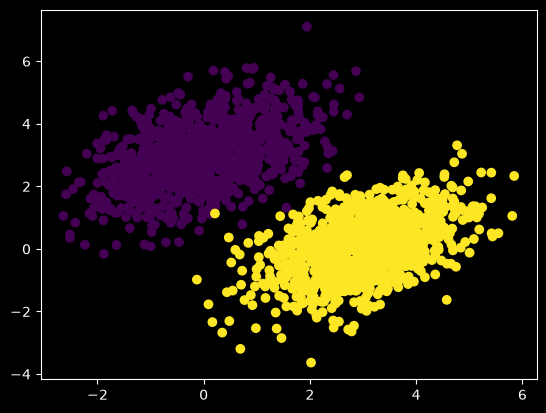

In [24]:
import matplotlib.pyplot as plt

plt.scatter(inputs[:, 0], inputs[:, 1], c=targets[:, 0])
plt.show()

In [ ]:
input_dim = 2
output_dim = 1
W = tf.Variable(initial_value=tf.random.uniform(shape=(input_dim, output_dim)))
b = tf.Variable(initial_value=tf.zeros(shape=(output_dim,)))

In [ ]:
def model(inputs, W, b):
    return tf.matmul(inputs, W) + b

In [ ]:
def mean_squared_error(targets, predictions):
    per_sample_losses = tf.square(targets - predictions)
    return tf.reduce_mean(per_sample_losses)

In [ ]:
learning_rate = 0.1

@tf.function(jit_compile=True)
def training_step(inputs, targets, W, b):
    with tf.GradientTape() as tape:
        predictions = model(inputs, W, b)
        loss = mean_squared_error(predictions, targets)
    grad_loss_wrt_W, grad_loss_wrt_b = tape.gradient(loss, [W, b])
    W.assign_sub(grad_loss_wrt_W * learning_rate)
    b.assign_sub(grad_loss_wrt_b * learning_rate)
    return loss

In [29]:
for step in range(40):
    loss = training_step(inputs, targets, W, b)
    print(f"{step}번째 스텝의 손실: {loss:.4f}")

0번째 스텝의 손실: 4.3572
1번째 스텝의 손실: 0.3494
2번째 스텝의 손실: 0.1470
3번째 스텝의 손실: 0.1163
4번째 스텝의 손실: 0.1063
5번째 스텝의 손실: 0.0994
6번째 스텝의 손실: 0.0932
7번째 스텝의 손실: 0.0876
8번째 스텝의 손실: 0.0825
9번째 스텝의 손실: 0.0778
10번째 스텝의 손실: 0.0735
11번째 스텝의 손실: 0.0695
12번째 스텝의 손실: 0.0659
13번째 스텝의 손실: 0.0626
14번째 스텝의 손실: 0.0596
15번째 스텝의 손실: 0.0568
16번째 스텝의 손실: 0.0542
17번째 스텝의 손실: 0.0519
18번째 스텝의 손실: 0.0498
19번째 스텝의 손실: 0.0478
20번째 스텝의 손실: 0.0460
21번째 스텝의 손실: 0.0444
22번째 스텝의 손실: 0.0429
23번째 스텝의 손실: 0.0415
24번째 스텝의 손실: 0.0402
25번째 스텝의 손실: 0.0391
26번째 스텝의 손실: 0.0380
27번째 스텝의 손실: 0.0370
28번째 스텝의 손실: 0.0361
29번째 스텝의 손실: 0.0353
30번째 스텝의 손실: 0.0346
31번째 스텝의 손실: 0.0339
32번째 스텝의 손실: 0.0333
33번째 스텝의 손실: 0.0327
34번째 스텝의 손실: 0.0322
35번째 스텝의 손실: 0.0317
36번째 스텝의 손실: 0.0312
37번째 스텝의 손실: 0.0308
38번째 스텝의 손실: 0.0305
39번째 스텝의 손실: 0.0301


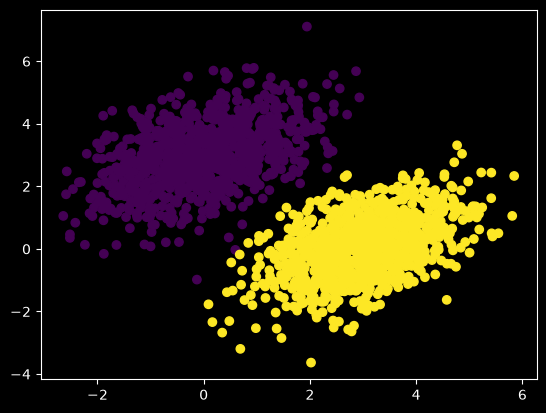

In [30]:
predictions = model(inputs, W, b)
plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5)
plt.show()

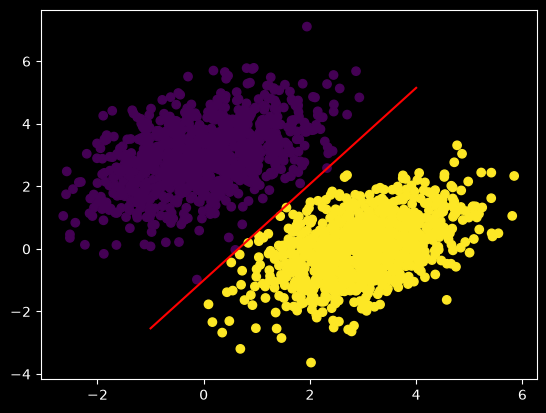

In [31]:
x = np.linspace(-1, 4, 100)
y = -W[0] / W[1] * x + (0.5 - b) / W[1]
plt.plot(x, y, "-r")
plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5)

#### 텐서플로 방식의 차이점